# Upload an STL and compare its CT reconstruction with ground truth (Colab)

This notebook uses **your STL** as the simulated object. It creates a clean, monochromatic gVXR scan, voxelizes the STL to make a ground-truth attenuation volume, reconstructs the projections with TIGRE FDK, then compares the reconstruction with ground truth using plots, attenuation error, RMSE, and Dice overlap.

**Colab setup:** choose a GPU runtime before running. TIGRE reconstruction requires CUDA and an NVIDIA GPU. gVXR uses OpenGL/EGL and can fall back to software rendering, which is slower. The notebook keeps gVXR calls on the project’s GL worker thread.

This compares a synthetic reconstruction against synthetic ground truth derived from the same STL; it is not a comparison against a physical scan.

## Before running
Upload these five files from the project: `ct_core.py`, `ct_variations.py`, `ct_voxel.cpp`, `build_voxel.py`. In the configuration cell, set the STL units, material type/name, density, scanner geometry, and scan size. Start with a watertight STL where possible; open meshes use the project’s approximate surface-fill method for the ground-truth volume.


## 1. Upload the project source files

Select `ct_core.py`, `ct_variations.py`, `ct_voxel.cpp`, `build_voxel.py`


In [1]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

required = [
    "ct_core.py",
    "ct_variations.py",
    "ct_voxel.cpp",
    "build_voxel.py",
]
missing = [name for name in required if not Path("/content", name).exists()]

if missing:
    raise FileNotFoundError("Upload these project files: " + ", ".join(missing))

print("Project files are ready. The notebook will create the cone mesh.")
import sys
import subprocess
from pathlib import Path

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "trimesh"
])

import trimesh

cone = trimesh.creation.cone(
    radius=10.0,   # mm
    height=25.0,   # mm
    sections=48
)

if not cone.is_watertight:
    raise RuntimeError("Generated cone is not watertight.")

STL_FILE = "/content/watertight_cone.stl"
cone.export(STL_FILE)

print("Created:", STL_FILE)
print("Watertight:", cone.is_watertight)
print("Bounds (mm):", cone.bounds.tolist())
print("Faces:", len(cone.faces))

Project files are ready. The notebook will create the cone mesh.
Created: /content/watertight_cone.stl
Watertight: True
Bounds (mm): [[-10.0, -10.0, 0.0], [10.0, 10.0, 25.0]]
Faces: 96


## 2. Install gVXR and system libraries

These are the Colab Linux libraries used by gVXR’s OpenGL/EGL bindings, including the XCB libraries needed by the Python extension.

In [2]:
import subprocess, sys
subprocess.run(['apt-get', 'update', '-qq'], check=True)
subprocess.run(['apt-get', 'install', '-y', '-qq',
    'build-essential', 'libgomp1', 'libxcb-res0', 'libxcb-xinerama0', 'libxcb-xkb1', 'libxcb-icccm4', 'libxcb-image0',
    'libxcb-keysyms1', 'libxcb-render-util0', 'libxcb-shape0', 'libxcb-randr0', 'libxkbcommon-x11-0',
    'libxrandr2', 'libxinerama1', 'libxcursor1', 'libxi6', 'libxxf86vm1',
    'libgl1', 'libegl1', 'libopengl0', 'libglu1-mesa', 'libgl1-mesa-dri', 'libegl-mesa0', 'libglx-mesa0',
    'libxcb-composite0', 'libxcb-cursor0', 'libxcb-dri2-0', 'libxcb-ewmh2',
    'libxcb-dri3-0', 'libxcb-glx0', 'libxcb-present0', 'libxcb-sync1', 'libxcb-xfixes0', 'libxcb-xinput0',
    'libxcb-util1', 'libxcb-xv0', 'libxcb-damage0', 'libxcb-dpms0', 'libxcb-record0', 'libxcb-screensaver0',
    'libxcb-shm0', 'libxcb-xtest0', 'libxcb-xf86dri0', 'libxcb-xvmc0'], check=True)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q',
    'gvxr', 'numpy', 'xraylib', 'trimesh', 'scipy', 'scikit-image', 'tifffile', 'h5py', 'matplotlib', 'pandas', 'pybind11'], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'gvxr', 'numpy', 'xraylib', 'trimesh', 'scipy', 'scikit-image', 'tifffile', 'h5py', 'matplotlib', 'pandas', 'pybind11'], returncode=0)

## 3. Build the project voxelizer with `build_voxel.py` and import the simulator

In [3]:
import importlib, sys
from pathlib import Path
import numpy as np

project_dir = Path('/content')
subprocess.check_call([sys.executable, str(project_dir / 'build_voxel.py')], cwd=project_dir)
importlib.invalidate_caches()
sys.path.insert(0, str(project_dir))
import ct_core as core
import ct_variations as variations
import ct_voxel
print('Project modules and C++ voxelizer loaded.')


Project modules and C++ voxelizer loaded.


## 4. Configure the material and clean monochromatic scan

Edit the values below. Set the STL units to the units used by your mesh, select its material model and name, and enter its density in g/cm³. The ground-truth voxel pitch is detector pixel size divided by magnification. Increase the pixel size or reduce detector dimensions if the object would create an excessively large volume.

Keep the scan monochromatic and detector effects disabled for this reconstruction comparison. The scan is simulated from the uploaded mesh, so choose source/detector distances and detector sampling that fit the object.


In [4]:
from pathlib import Path

OBJECT_NAME = Path(STL_FILE).stem
OBJECT_KIND = 'Element'       # Element, Compound, or Mixture
MATERIAL = 'Al'               # examples: Al, Cu, H2O, Ti90Al6V4
DENSITY_G_CM3 = 2.70
STL_UNIT = 'mm'               # mm, cm, m, or um
CENTER_MESH_AT_ORIGIN = True
OBJECT_OFFSET_MM = (0.0, 0.0, 0.0)
OBJECT_ROTATION_DEG = (0.0, 0.0, 0.0)

ENERGY_KEV = 80.0
PHOTONS_PER_RAY = 10000
SOD_CM = 40.0
DETECTOR_DISTANCE_FROM_AXIS_CM = 10.0
NX, NY = 320, 160
DETECTOR_PIXEL_MM = 1.0
N_ANGLES = 180
TOTAL_ANGLE_DEG = 360.0
OUTPUT_H5 = '/content/user_stl_clean_scan.h5'

print('Source-to-detector distance (cm):', SOD_CM + DETECTOR_DISTANCE_FROM_AXIS_CM)
print('Magnification:', (SOD_CM + DETECTOR_DISTANCE_FROM_AXIS_CM) / SOD_CM)
print('Expected ground-truth voxel pitch (mm):', DETECTOR_PIXEL_MM / ((SOD_CM + DETECTOR_DISTANCE_FROM_AXIS_CM) / SOD_CM))


Source-to-detector distance (cm): 50.0
Magnification: 1.25
Expected ground-truth voxel pitch (mm): 0.8


## 5. Build the scan configuration and inspect renderer

In [5]:
obj = core.ObjectCfg(OBJECT_NAME, STL_FILE, OBJECT_KIND, MATERIAL, DENSITY_G_CM3,
                     tuple(OBJECT_OFFSET_MM), tuple(OBJECT_ROTATION_DEG))
cfg = core.ScanCfg(objects=[obj], stl_unit=STL_UNIT, center_each=CENTER_MESH_AT_ORIGIN,
                   beam='Cone', source_x_cm=SOD_CM, detector_x_cm=DETECTOR_DISTANCE_FROM_AXIS_CM,
                   energy_kev=ENERGY_KEV, photons=PHOTONS_PER_RAY, nx=NX, ny=NY,
                   pixel_mm=DETECTOR_PIXEL_MM, n_angles=N_ANGLES, total_deg=TOTAL_ANGLE_DEG,
                   noise=False, seed=0, spectrum=None)
for warning in core.configuration_warnings(cfg):
    print('WARNING:', warning)
renderer = core.on_gl_thread(lambda: (core._gx(), core.renderer_info())[1])
print('Renderer selection:', core.renderer_selection_info())
print('Active OpenGL renderer:', renderer)


[gVXR] Renderer selection: Registered NVIDIA EGL before gVXR context creation.
[gVXR] OpenGL context: {'vendor': 'NVIDIA Corporation', 'renderer': 'Tesla T4/PCIe/SSE2', 'version': '4.3.0 NVIDIA 580.82.07'}
Renderer selection: {'requested': 'auto', 'platform': 'linux', 'selected_driver': 'NVIDIA EGL', 'nvidia_egl_library': '/usr/lib64-nvidia/libEGL_nvidia.so.0', 'egl_vendor_json': '/tmp/ct_simulator_egl_vendor/10_nvidia.json', 'message': 'Registered NVIDIA EGL before gVXR context creation.'}
Active OpenGL renderer: {'vendor': 'NVIDIA Corporation', 'renderer': 'Tesla T4/PCIe/SSE2', 'version': '4.3.0 NVIDIA 580.82.07'}


## 6. Acquire all views (clean data)

The acquisition is split into chunks to limit temporary memory use. Each gVXR call is dispatched to the same GL worker thread, preserving the context-thread requirement.

In [6]:
flat = core.on_gl_thread(core.build_scene, cfg)
step_deg = TOTAL_ANGLE_DEG / N_ANGLES
chunk_size = max(1, N_ANGLES // 10)
chunks = []
completed = 0
while completed < N_ANGLES:
    count = min(chunk_size, N_ANGLES - completed)
    chunks.append(core.on_gl_thread(core.acquire, count, step_deg))
    completed += count
    print(f'Acquired {completed}/{N_ANGLES} projections')
raw = np.concatenate(chunks, axis=0).astype(np.float32)

# Default EffectsCfg values give an ideal detector.
fx = variations.EffectsCfg(seed=0)
atten, projection_counts, flat_counts = variations.apply_effects(raw, flat, cfg.photons, fx)
angles_deg = core.angles(cfg).astype(np.float32)
print('Projection shape:', atten.shape, 'Expected:', (N_ANGLES, NY, NX))
print('Attenuation range:', float(atten.min()), 'to', float(atten.max()))


Acquired 18/180 projections
Acquired 36/180 projections
Acquired 54/180 projections
Acquired 72/180 projections
Acquired 90/180 projections
Acquired 108/180 projections
Acquired 126/180 projections
Acquired 144/180 projections
Acquired 162/180 projections
Acquired 180/180 projections
Projection shape: (180, 160, 320) Expected: (180, 160, 320)
Attenuation range: -0.0 to 1.0486505031585693


## 7. Generate ground truth and save the clean scan

The project voxelizes the uploaded STL. Ground-truth attenuation is calculated at the selected monochromatic energy from the configured material and density.


In [7]:
import json
from dataclasses import asdict
import h5py
import numpy as np

voxelizer_calls = []
original_voxelize = ct_voxel.voxelize

def tracked_voxelize(vertices, faces, *args, **kwargs):
    mask = original_voxelize(vertices, faces, *args, **kwargs)
    voxelizer_calls.append({
        "vertices": len(vertices),
        "faces": len(faces),
        "occupied_voxels": int(np.count_nonzero(mask)),
    })
    return mask

ct_voxel.voxelize = tracked_voxelize
try:
    labels, mu_gt, gt_meta = core.ground_truth_volumes(cfg)
finally:
    ct_voxel.voxelize = original_voxelize

print("C++ voxelizer calls:", len(voxelizer_calls))
for i, call in enumerate(voxelizer_calls, start=1):
    print(f"Mesh {i}: {call}")

if voxelizer_calls:
    print("CONFIRMED: the C++ voxelizer was used.")
else:
    print("No C++ voxelizer calls were recorded.")
with h5py.File(OUTPUT_H5, 'w') as h:
    h.attrs['sample_id'] = 0
    h.attrs['scan_config_json'] = json.dumps(asdict(cfg), default=str)
    h.attrs['effects_json'] = json.dumps(asdict(fx), default=str)
    h.attrs['ground_truth_json'] = json.dumps(gt_meta)
    h.create_dataset('projection/attenuation', data=atten.astype(np.float32),
                     chunks=(1, min(NY,64), min(NX,128)), compression='gzip', compression_opts=4, shuffle=True)
    h.create_dataset('projection/raw_counts', data=projection_counts.astype(np.float32),
                     chunks=(1, min(NY,64), min(NX,128)), compression='gzip', compression_opts=4, shuffle=True)
    h.create_dataset('detector/flat_counts', data=flat_counts.astype(np.float32),
                     compression='gzip', compression_opts=4, shuffle=True)
    h.create_dataset('ground_truth/labels', data=labels, chunks=True, compression='gzip', compression_opts=4, shuffle=True)
    h.create_dataset('ground_truth/attenuation_cm_inv', data=mu_gt.astype(np.float32),
                     chunks=True, compression='gzip', compression_opts=4, shuffle=True)
    h.create_dataset('angles_deg', data=angles_deg)
print('Wrote', OUTPUT_H5)
print('Ground truth shape (x,y,z):', labels.shape, 'metadata:', gt_meta)


C++ voxelizer calls: 1
Mesh 1: {'vertices': 50, 'faces': 96, 'occupied_voxels': 5280}
CONFIRMED: the C++ voxelizer was used.
Wrote /content/user_stl_clean_scan.h5
Ground truth shape (x,y,z): (28, 28, 34) metadata: {'axis_order': 'x,y,z', 'origin_mm': [-11.200000000000001, -11.200000000000001, -13.600000000000001], 'voxel_size_mm': 0.8, 'label_map': {'0': 'background', '1': 'watertight_cone'}, 'attenuation_energy_kev': 80.0, 'attenuation_units': 'cm^-1', 'attenuation_method': 'xraylib total mass attenuation coefficient times density'}


## 8. Inspect and download the sample

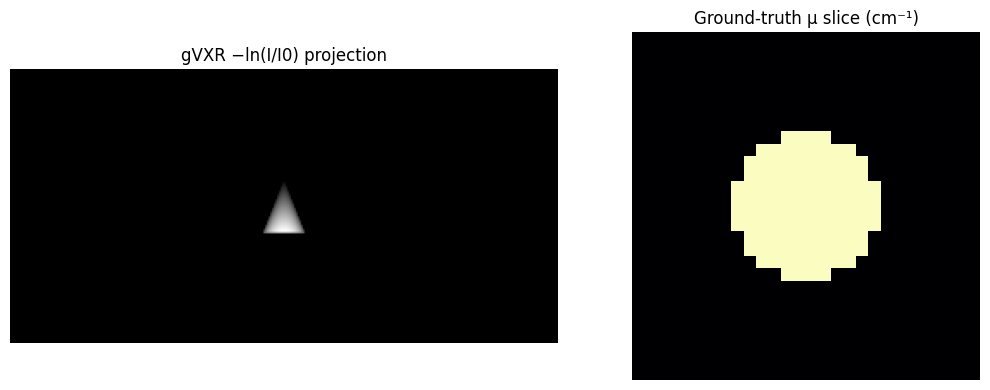

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
import matplotlib.pyplot as plt
with h5py.File(OUTPUT_H5, 'r') as h:
    sample_projection = h['projection/attenuation'][N_ANGLES // 4]
    sample_gt = h['ground_truth/attenuation_cm_inv'][:]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(sample_projection, cmap='gray'); ax[0].set_title('gVXR −ln(I/I0) projection')
ax[1].imshow(sample_gt[:, :, sample_gt.shape[2] // 2].T, cmap='magma'); ax[1].set_title('Ground-truth μ slice (cm⁻¹)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

from google.colab import files
files.download(OUTPUT_H5)


## 8. Check for a CUDA GPU

TIGRE FDK requires an NVIDIA GPU in this Colab runtime. If unavailable, switch Runtime → Change runtime type → T4 GPU and reconnect.

In [9]:
!nvidia-smi


Mon Oct 26 18:29:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             13W /   70W |      16MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

If this cell says no NVIDIA GPU is available, change the Colab runtime to GPU and reconnect before continuing.

## 9. Install TIGRE

This builds TIGRE from its CERN source repository using the CUDA compiler in the active Colab runtime.

In [10]:
%cd /content
!if [ ! -d /content/TIGRE/.git ]; then git clone --depth 1 https://github.com/CERN/TIGRE.git; fi
%cd /content/TIGRE
import os, shutil, subprocess, sys
from pathlib import Path

nvcc = shutil.which('nvcc')
if nvcc is None:
    candidates = sorted(Path('/usr/local').glob('cuda*/bin/nvcc'))
    nvcc = str(candidates[-1]) if candidates else None
if nvcc is None:
    raise RuntimeError('TIGRE source build requires the CUDA compiler (nvcc). Confirm Colab is using a GPU runtime; if nvcc is still missing, this runtime cannot compile TIGRE.')
cuda_home = str(Path(nvcc).resolve().parent.parent)
os.environ['CUDA_HOME'] = cuda_home
os.environ['CUDA_PATH'] = cuda_home
os.environ['PATH'] = str(Path(nvcc).resolve().parent) + os.pathsep + os.environ.get('PATH', '')
print('Using CUDA_HOME:', cuda_home)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'Cython', 'wheel', 'setuptools'])
# Build against the CUDA libraries available in this Colab runtime.
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--no-build-isolation', '-v', '.'])
%cd /content


/content
Cloning into 'TIGRE'...
remote: Enumerating objects: 436, done.
remote: Counting objects: 100% (436/436), done.
remote: Compressing objects: 100% (381/381), done.
remote: Total 436 (delta 106), reused 130 (delta 43), pack-reused 0 (from 0)
Receiving objects: 100% (436/436), 37.46 MiB | 14.86 MiB/s, done.
Resolving deltas: 100% (106/106), done.
/content/TIGRE
Using CUDA_HOME: /usr/local/cuda-13.0
/content


In [11]:
import numpy as np
import tigre
import tigre.algorithms as algs
print('TIGRE imported:', getattr(tigre, '__version__', 'version not exposed'))


TIGRE imported: version not exposed


## 10. Load the generated scan and ground truth

This reads the HDF5 file created earlier in this notebook and confirms it is clean, monochromatic cone-beam data.

In [12]:
import json, h5py
import numpy as np
import pandas as pd

h5_path = OUTPUT_H5
with h5py.File(h5_path, 'r') as h:
    proj = h['projection/attenuation'][:].astype(np.float32)
    angles_deg = h['angles_deg'][:].astype(np.float32)
    labels_xyz = h['ground_truth/labels'][:]
    truth_xyz = h['ground_truth/attenuation_cm_inv'][:].astype(np.float32)
    saved_cfg = json.loads(h.attrs['scan_config_json'])
    gt_meta = json.loads(h.attrs['ground_truth_json'])
    effects = json.loads(h.attrs.get('effects_json', '{}'))
cfg = saved_cfg

print('Projection array:', proj.shape, '(angle, detector row, detector column)')
print('Ground-truth array:', truth_xyz.shape, '(x,y,z)')
print('Ground-truth metadata:', gt_meta)
if saved_cfg.get('beam') != 'Cone':
    raise ValueError('This notebook expects cone-beam geometry.')
if saved_cfg.get('spectrum') not in (None, {}, '') or saved_cfg.get('noise', False):
    raise ValueError('Use clean monochromatic data.')
if effects and any(float(effects.get(k, 0) or 0) != 0 for k in
                   ['psf_sigma_px','scatter_frac','gain_sigma','flat_mismatch_sigma','read_noise','dark_offset']):
    raise ValueError('Detector effects must be disabled for this comparison.')
if effects.get('poisson', False):
    raise ValueError('Poisson noise must be disabled for this comparison.')


Projection array: (180, 160, 320) (angle, detector row, detector column)
Ground-truth array: (28, 28, 34) (x,y,z)
Ground-truth metadata: {'axis_order': 'x,y,z', 'origin_mm': [-11.200000000000001, -11.200000000000001, -13.600000000000001], 'voxel_size_mm': 0.8, 'label_map': {'0': 'background', '1': 'watertight_cone'}, 'attenuation_energy_kev': 80.0, 'attenuation_units': 'cm^-1', 'attenuation_method': 'xraylib total mass attenuation coefficient times density'}


## 4. Build TIGRE cone geometry from saved metadata

Distances and detector dimensions follow the project’s `geometry.json` definitions. TIGRE geometry uses voxel order `(z, y, x)` for Python volumes; the stored ground truth is `(x, y, z)`, so it is transposed below for comparison. The GT origin is converted to a volume-center offset.


In [13]:
SOD = float(cfg['source_x_cm']) * 10.0
SDD = (float(cfg['source_x_cm']) + float(cfg['detector_x_cm'])) * 10.0
px = float(cfg['pixel_mm'])
mag = SDD / SOD
voxel_mm = float(gt_meta['voxel_size_mm'])
voxel_expected_mm = px / mag

if not np.isclose(voxel_mm, voxel_expected_mm, rtol=1e-4, atol=1e-6):
    print(f'WARNING: GT voxel pitch {voxel_mm:g} mm differs from pixel/magnification {voxel_expected_mm:g} mm.')

ny, nx = int(cfg['ny']), int(cfg['nx'])
if proj.shape[1:] != (ny, nx):
    raise ValueError(f'Projection detector shape {proj.shape[1:]} != config {(ny, nx)}')

# TIGRE volumes use (z, y, x); saved ground truth uses (x, y, z).
nx_gt, ny_gt, nz_gt = truth_xyz.shape
geo = tigre.geometry()
geo.mode = 'cone'
geo.DSD, geo.DSO = SDD, SOD
geo.nDetector = np.array([ny, nx], dtype=np.int32)
geo.dDetector = np.array([px, px], dtype=np.float32)
geo.sDetector = geo.nDetector * geo.dDetector
geo.nVoxel = np.array([nz_gt, ny_gt, nx_gt], dtype=np.int32)
geo.dVoxel = np.array([voxel_mm, voxel_mm, voxel_mm], dtype=np.float32)
geo.sVoxel = geo.nVoxel * geo.dVoxel
geo.offDetector = np.array([0.0, 0.0], dtype=np.float32)
geo.rotDetector = np.array([0.0, 0.0, 0.0], dtype=np.float32)
geo.accuracy = 0.5

# Align the volume center with the saved ground-truth grid.
origin_xyz = np.asarray(gt_meta['origin_mm'], dtype=float)
shape_xyz = np.asarray(truth_xyz.shape, dtype=float)
volume_center_xyz = origin_xyz + 0.5 * shape_xyz * voxel_mm
geo.offOrigin = volume_center_xyz.astype(np.float32)

ang = np.deg2rad(angles_deg).astype(np.float32)
print(f'SOD={SOD:.3f} mm, SDD={SDD:.3f} mm, magnification={mag:.5f}')
print('TIGRE nVoxel (z,y,x):', geo.nVoxel, 'voxel pitch:', geo.dVoxel, 'mm')
print('TIGRE offOrigin (x,y,z) mm:', geo.offOrigin)


SOD=400.000 mm, SDD=500.000 mm, magnification=1.25000
TIGRE nVoxel (z,y,x): [34 28 28] voxel pitch: [0.8 0.8 0.8] mm
TIGRE offOrigin (x,y,z) mm: [0. 0. 0.]


## 5. Reconstruct with FDK

FDK is the standard approximate filtered backprojection for circular cone-beam scans. TIGRE’s geometry fields and `fdk(projections, geo, angles)` follow the official Python examples.


In [14]:
# Start with the saved angle sign and detector orientation.
recon_mm_inv = algs.fdk(proj, geo, ang).astype(np.float32)
print('FDK volume shape:', recon_mm_inv.shape, '(expected TIGRE z,y,x)')
print('FDK range (mm^-1):', float(np.nanmin(recon_mm_inv)), float(np.nanmax(recon_mm_inv)))

# Interpret FDK output as mm^-1.
recon_cm_inv = recon_mm_inv * 10.0
truth_zyx = np.transpose(truth_xyz, (2, 1, 0))
labels_zyx = np.transpose(labels_xyz, (2, 1, 0))
if recon_cm_inv.shape != truth_zyx.shape:
    raise ValueError(f'Reconstruction shape {recon_cm_inv.shape} != GT z,y,x {truth_zyx.shape}. Check TIGRE version/geometry ordering.')


FDK volume shape: (34, 28, 28) (expected TIGRE z,y,x)
FDK range (mm^-1): -0.004907897207885981 0.06391994655132294


## 6. Compare orientation conventions

The saved gVXR detector up-vector and +z scene rotation may differ from TIGRE’s sign or axis orientation. This cell evaluates the eight simple volume flips and both angle signs as a **diagnostic**. It does not silently choose and overwrite the reconstruction. Use the asymmetric-object case and inspect the plots before selecting a convention. A flip of projection detector columns/rows requires rerunning FDK with that flipped projection array.


In [15]:
from itertools import product
from scipy.ndimage import binary_erosion
import pandas as pd

# Compare reconstructions for each angle sign and axis flip.
# Use the plots and saved geometry to choose the convention.
orient_rows = []
recon_candidates = {}
for sign in (1.0, -1.0):
    r = algs.fdk(proj, geo, ang * sign).astype(np.float32) * 10.0
    for flips in product((False, True), repeat=3):
        rr = np.flip(r, axis=tuple(i for i, f in enumerate(flips) if f)) if any(flips) else r
        rmse = float(np.sqrt(np.mean((rr - truth_zyx) ** 2)))
        key = (int(sign), flips)
        recon_candidates[key] = rr.copy()
        orient_rows.append({'angle_sign': int(sign), 'flip_z': flips[0], 'flip_y': flips[1],
                            'flip_x': flips[2], 'RMSE_cm_inv': rmse})
orientation_table = pd.DataFrame(orient_rows).sort_values('RMSE_cm_inv').reset_index(drop=True)
display(orientation_table.head(8))
print('Treat the best row as a candidate only. Confirm it visually and with an asymmetric phantom.')


,angle_sign,flip_z,flip_y,flip_x,RMSE_cm_inv
0,1,True,True,True,0.046388
1,1,True,True,False,0.046388
2,1,True,False,True,0.046388
3,1,True,False,False,0.046388
4,-1,True,False,False,0.046388
5,-1,True,False,True,0.046388
6,-1,True,True,False,0.046388
7,-1,True,True,True,0.046388


Treat the best row as a candidate only. Confirm it visually and with an asymmetric phantom.


## 7. Metrics: per-material mean μ, RMSE, and Dice

Set the selected angle sign and reconstruction-axis flips after reviewing the orientation candidates. Metrics use the full aligned grid for RMSE; material means and Dice are computed per non-background label. Edge erosion reduces partial-volume effects. Dice classifies every voxel, including background, to its nearest ground-truth μ value so false positives count. This is a simple baseline; for very similar material μ values, use hand-chosen thresholds instead.


In [16]:
# Confirmed against the uploaded lizard STL: flip the reconstructed z axis.
# Check the orientation table again when using a different scan or coordinate convention.
SELECTED_ANGLE_SIGN = 1
SELECTED_FLIPS_ZYX = (True, False, False)

selected = recon_candidates[(SELECTED_ANGLE_SIGN, SELECTED_FLIPS_ZYX)]
# Segment by assigning each voxel to its nearest stored μ value.
label_map = gt_meta.get('label_map', {})
material_labels = [int(k) for k in label_map.keys() if int(k) != 0]
if not material_labels:
    material_labels = [int(v) for v in np.unique(labels_zyx) if int(v) != 0]

metrics = []
rmse = float(np.sqrt(np.mean((selected - truth_zyx) ** 2)))
mu_values = np.array([float(np.mean(truth_zyx[labels_zyx == lab])) for lab in material_labels])
valid_labels = np.array(material_labels, dtype=np.int32)
# Include background so false positives count in Dice.
class_labels = np.concatenate(([0], valid_labels))
class_mu = np.concatenate(([0.0], mu_values))
nearest = class_labels[np.argmin(np.abs(selected[..., None] - class_mu[None, None, None, :]), axis=-1)]
for lab, target_mu in zip(material_labels, mu_values):
    mask = labels_zyx == lab
    eroded = binary_erosion(mask, iterations=2, border_value=0)
    if eroded.sum() < 10:
        eroded = mask
    measured_mu = float(np.mean(selected[eroded]))
    pred = nearest == lab
    denom = int(pred.sum() + mask.sum())
    dice = float(2 * np.logical_and(pred, mask).sum() / denom) if denom else 1.0
    metrics.append({'label': lab, 'material': label_map.get(str(lab), f'label_{lab}'),
                    'ground_truth_mean_mu_cm^-1': float(target_mu),
                    'reconstruction_mean_mu_cm^-1': measured_mu,
                    'mean_mu_error_percent': float(100 * (measured_mu-target_mu) / target_mu) if target_mu else np.nan,
                    'RMSE_full_volume_cm^-1': rmse, 'Dice': dice,
                    'voxels_used_for_mean': int(eroded.sum())})
metrics_df = pd.DataFrame(metrics)
display(metrics_df.set_index('label'))


,material,ground_truth_mean_mu_cm^-1,reconstruction_mean_mu_cm^-1,mean_mu_error_percent,RMSE_full_volume_cm^-1,Dice,voxels_used_for_mean
label,,,,,,,
1,watertight_cone,0.544795,0.544533,-0.04815,0.046388,0.988636,2608


## 8. Inspect slices and save results

Look for alignment, orientation, edge blur, cupping, and cone-beam artifacts. FDK is approximate; poor-looking peripheral slices do not automatically imply a broken forward model. If the object is off-center, the saved ground-truth origin and TIGRE `offOrigin` mapping need careful coordinate-frame confirmation.


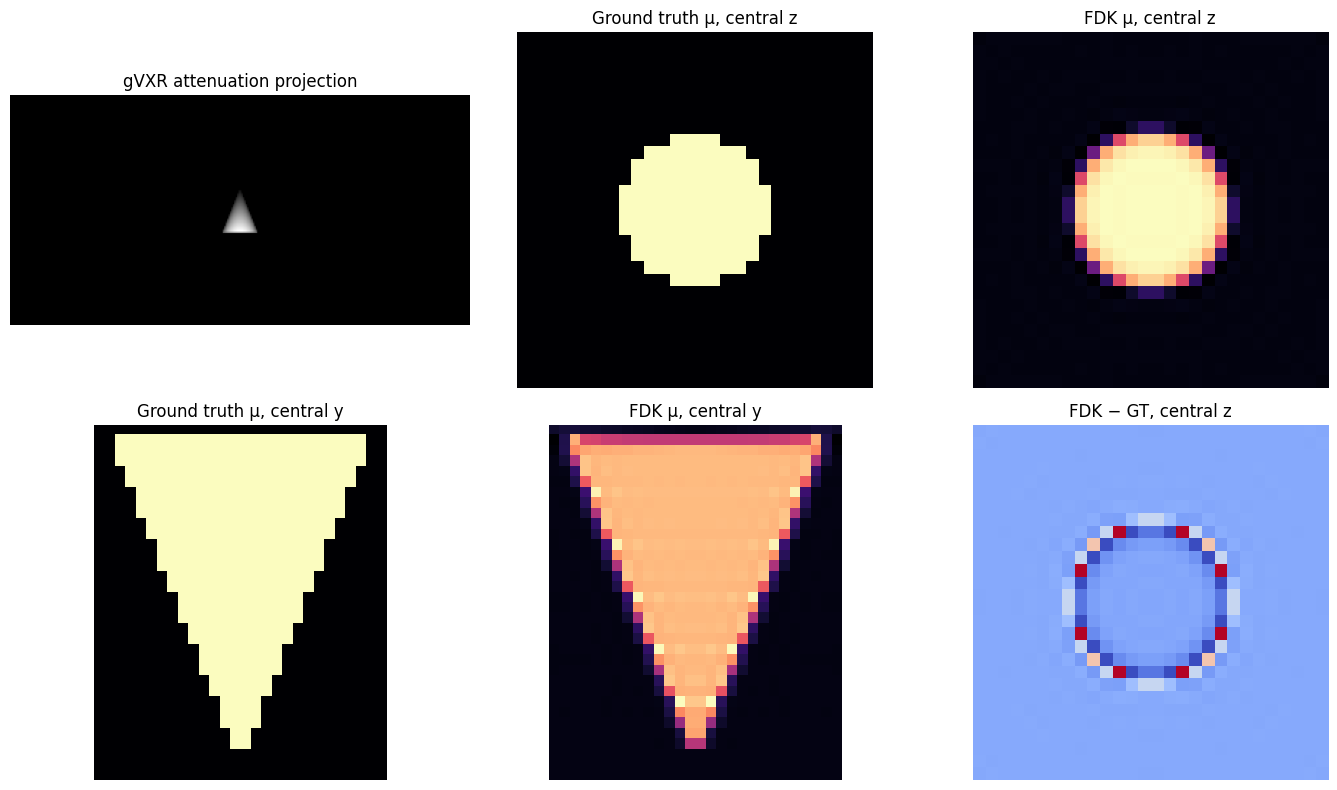

Saved: tigre_reconstruction_cm_inv.npy, tigre_validation_metrics.csv, tigre_validation_summary.json


In [17]:
import matplotlib.pyplot as plt

zmid, ymid, xmid = (np.array(selected.shape) // 2).tolist()
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
ax[0,0].imshow(proj[len(proj)//4, :, :], cmap='gray'); ax[0,0].set_title('gVXR attenuation projection')
ax[0,1].imshow(truth_zyx[zmid], cmap='magma'); ax[0,1].set_title('Ground truth μ, central z')
ax[0,2].imshow(selected[zmid], cmap='magma'); ax[0,2].set_title('FDK μ, central z')
ax[1,0].imshow(truth_zyx[:, ymid, :], cmap='magma'); ax[1,0].set_title('Ground truth μ, central y')
ax[1,1].imshow(selected[:, ymid, :], cmap='magma'); ax[1,1].set_title('FDK μ, central y')
ax[1,2].imshow(selected[zmid] - truth_zyx[zmid], cmap='coolwarm'); ax[1,2].set_title('FDK − GT, central z')
for a in ax.flat: a.axis('off')
plt.tight_layout(); plt.show()

np.save('tigre_reconstruction_cm_inv.npy', selected)
metrics_df.to_csv('tigre_validation_metrics.csv', index=False)
with open('tigre_validation_summary.json', 'w') as f:
    json.dump({'source_h5': h5_path, 'SOD_mm': SOD, 'SDD_mm': SDD,
               'magnification': mag, 'voxel_size_mm': voxel_mm,
               'angle_sign': SELECTED_ANGLE_SIGN, 'flips_zyx': SELECTED_FLIPS_ZYX,
               'global_RMSE_cm_inv': rmse, 'materials': metrics}, f, indent=2)
print('Saved: tigre_reconstruction_cm_inv.npy, tigre_validation_metrics.csv, tigre_validation_summary.json')


## Interpretation notes

- The uploaded STL defines the simulated object's shape. Confirm material type, material name, density, and mesh units before interpreting attenuation values.
- The C++ voxelizer is used for watertight meshes. Open meshes use the project's approximate surface-fill method, so their ground truth can be less reliable.
- This notebook assigns one material to the whole uploaded STL. For multiple material regions, use separate meshes with a per-part configuration.
- TIGRE output is converted from mm⁻¹ to cm⁻¹ before comparison. Keep the scan monochromatic and detector effects disabled.
- FDK is approximate. Edge blur and cone-beam artifacts can produce differences from the voxel ground truth. Confirm orientation, centering, and units before interpreting the metrics.
- This is a synthetic reconstruction-vs-ground-truth comparison, not validation against a physical scan.
